<center>

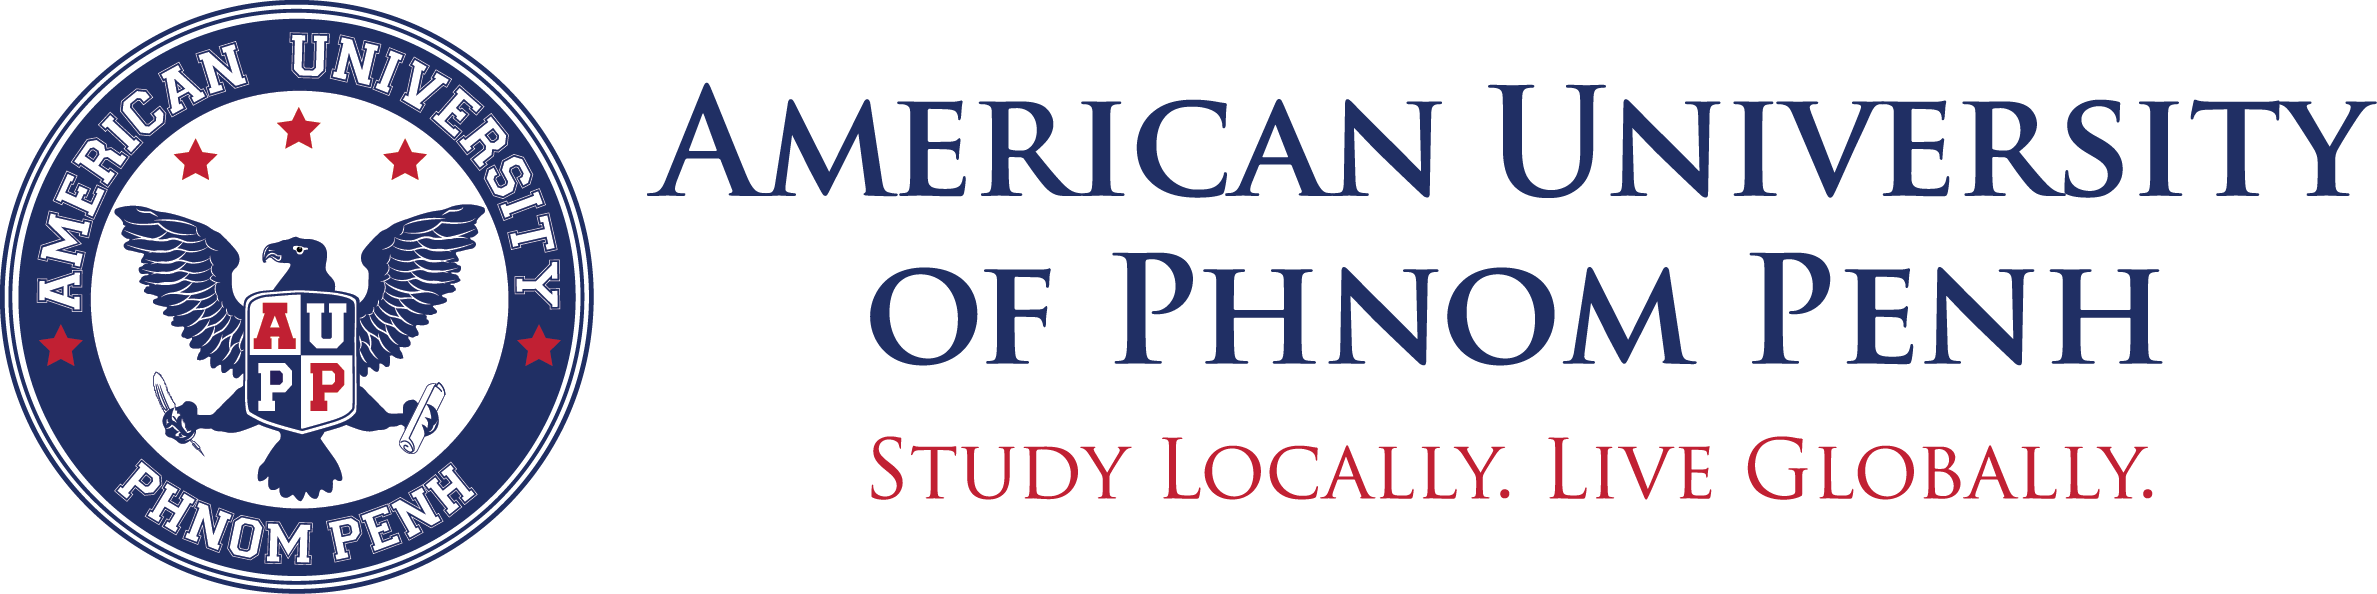

### School of Digital Technologies  
#### ITM-360: Artificial Intelligence
#### Lab-Practice: Softmax Regression Implementation from Scratch
 
**Lecturer:** Kuntha Pin (Ph.D Eng.)

</center>

---

### Contents
### 1. Introduction
### 2. The Model
### 3. The Cross-Entropy Loss
### 4. Training 
### 5. Prediction
### 6. Summary
---

# 1. Introduction

### Softmax Regression from scratch is a fundamental exercise in understanding how multi-class classification models transform raw data into probability distributions.   
  

In [2]:
# Import necessary libraries

import numpy as np
import struct
import matplotlib.pyplot as plt

- Additional resources: https://d2l.ai/chapter_linear-classification/softmax-regression-scratch.html

# 2. The Model

We now have everything that we need to implement the softmax regression model. As in our linear regression example, each instance will be represented by a fixed-length vector. Since the raw data here consists of 28 x 28 pixel images, we flatten each image, treating them as vectors of length 784. 

In softmax regression, the number of outputs from our network should be equal to the number of classes. Since our dataset has 10 classes, our network has an output dimension of 10.

- Load MNIST From Raw IDX Files, it's really important when using NumPy library

In [5]:
def load_mnist_images(filename):
    """
    Load MNIST-style images from IDX file.
    """
    with open(filename, 'rb') as f:
        magic, num, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        images = images.reshape(num, rows * cols)
        return images / 255.0  # normalize to [0,1]

def load_mnist_labels(filename):
    """
    Load MNIST-style labels from IDX file.
    """
    with open(filename, 'rb') as f:
        magic, num = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
        return labels

In [6]:
X_train = load_mnist_images("Fashion-MNIST/train-images-idx3-ubyte")
y_train = load_mnist_labels("Fashion-MNIST/train-labels-idx1-ubyte")

X_test = load_mnist_images("Fashion-MNIST/t10k-images-idx3-ubyte")
y_test = load_mnist_labels("Fashion-MNIST/t10k-labels-idx1-ubyte")

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (60000, 784) (60000,)
Test: (10000, 784) (10000,)


 - Computing the softmax requires three steps:   
(i) exponentiation of each term;   
(ii) a sum over each row to compute the normalization constant for each example;   
(iii) division of each row by its normalization constant, ensuring that the result sums to 1: 

$$
\mathrm{softmax}(\mathbf{X})_{ij}
=
\frac{
\exp\left(\mathbf{X}_{ij}\right)
}{
\sum_{k} \exp\left(\mathbf{X}_{ik}\right)
}.
$$

- Created the Softmax function

In [7]:
def softmax(X):
    X_shifted = X - np.max(X, axis=1, keepdims=True)
    exp_X = np.exp(X_shifted)
    return exp_X / np.sum(exp_X, axis=1, keepdims=True)

# 3. The Cross-Entropy Loss

Next, we implement the cross-entropy loss, one of the most common loss functions in deep learning. Since Softmax outputs probabilities, cross-entropy naturally measures how close those predictions are to the true distribution, making it ideal for classification tasks.

In [ ]:
def cross_entropy(y_hat, y):
    N = y.shape[0]
    return -np.mean(np.log(y_hat[np.arange(N), y] + 1e-9))

In [ ]:
def accuracy(y_hat, y):
    return np.mean(np.argmax(y_hat, axis=1) == y)

# 4. Training

Before traing, using One-Hot encoding is really important because:  
- True labels in the dataset are integers (0–9 for Fashion‑MNIST).
- The model output is a vector of probabilities from softmax:   $\hat{Y} = [0.05, 0.10, 0.80, \ldots, 0.01]$   
- To compute the gradient for learning, we need:    $error = \hat{Y} - Y$
- But Y must be in the same format as $\hat{Y}$   
    => That’s exactly what one-hot encoding does:   $y=2⇒Y=[0,0,1,0,0,0,0,0,0,0]$

In [ ]:
def one_hot(y, num_classes):
    return np.eye(num_classes)[y]

In [ ]:
def initialize_params(num_features, num_classes):
    W = np.random.normal(0, 0.01, (num_features, num_classes))
    b = np.zeros((1, num_classes))
    return W, b

In [ ]:
def forward(X, W, b):
    return softmax(np.dot(X, W) + b)

def compute_gradients(X, y, W, b):
    N = X.shape[0]
    y_hat = forward(X, W, b)
    y_onehot = one_hot(y, W.shape[1])

    error = y_hat - y_onehot
    dW = np.dot(X.T, error) / N
    db = np.sum(error, axis=0, keepdims=True) / N

    return dW, db

- Training Part

In [ ]:
def train(X_train, y_train, X_test, y_test,
          epochs=15, lr=0.1, batch_size=256):
    
    num_samples, num_features = X_train.shape
    num_classes = 10
    
    W, b = initialize_params(num_features, num_classes)
    
    train_losses, test_losses = [], []
    train_accs, test_accs = [], []
    
    for epoch in range(epochs):
        indices = np.random.permutation(num_samples)
        X_train = X_train[indices]
        y_train = y_train[indices]
        
        for i in range(0, num_samples, batch_size):
            X_batch = X_train[i:i+batch_size]
            y_batch = y_train[i:i+batch_size]
            
            dW, db = compute_gradients(X_batch, y_batch, W, b)
            W -= lr * dW
            b -= lr * db
        
        # Evaluate
        y_train_hat = forward(X_train, W, b)
        y_test_hat = forward(X_test, W, b)
        
        train_loss = cross_entropy(y_train_hat, y_train)
        test_loss = cross_entropy(y_test_hat, y_test)
        
        train_acc = accuracy(y_train_hat, y_train)
        test_acc = accuracy(y_test_hat, y_test)
        
        train_losses.append(train_loss)
        test_losses.append(test_loss)
        train_accs.append(train_acc)
        test_accs.append(test_acc)
        
        print(f"Epoch {epoch+1}: "
              f"Train Loss={train_loss:.4f}, "
              f"Train Acc={train_acc:.4f}, "
              f"Test Acc={test_acc:.4f}")
    
    return W, b, train_losses, test_losses, train_accs, test_accs

- By using 20 of epochs

In [ ]:
W, b, train_losses, test_losses, train_accs, test_accs = train(
    X_train, y_train, X_test, y_test,
    epochs=20, lr=0.1, batch_size=256
)

Epoch 1: Train Loss=0.6258, Train Acc=0.7883, Test Acc=0.7728
Epoch 2: Train Loss=0.5476, Train Acc=0.8161, Test Acc=0.8062
Epoch 3: Train Loss=0.5143, Train Acc=0.8266, Test Acc=0.8142
Epoch 4: Train Loss=0.4958, Train Acc=0.8322, Test Acc=0.8195
Epoch 5: Train Loss=0.4792, Train Acc=0.8386, Test Acc=0.8248
Epoch 6: Train Loss=0.4646, Train Acc=0.8438, Test Acc=0.8314
Epoch 7: Train Loss=0.4590, Train Acc=0.8457, Test Acc=0.8312
Epoch 8: Train Loss=0.4507, Train Acc=0.8478, Test Acc=0.8335
Epoch 9: Train Loss=0.4603, Train Acc=0.8395, Test Acc=0.8215
Epoch 10: Train Loss=0.4480, Train Acc=0.8478, Test Acc=0.8329
Epoch 11: Train Loss=0.4462, Train Acc=0.8462, Test Acc=0.8293
Epoch 12: Train Loss=0.4360, Train Acc=0.8509, Test Acc=0.8346
Epoch 13: Train Loss=0.4428, Train Acc=0.8488, Test Acc=0.8338
Epoch 14: Train Loss=0.4467, Train Acc=0.8481, Test Acc=0.8325
Epoch 15: Train Loss=0.4278, Train Acc=0.8535, Test Acc=0.8389
Epoch 16: Train Loss=0.4250, Train Acc=0.8553, Test Acc=0.8365
E

- Then we plot the graph to visual the loss from train and test

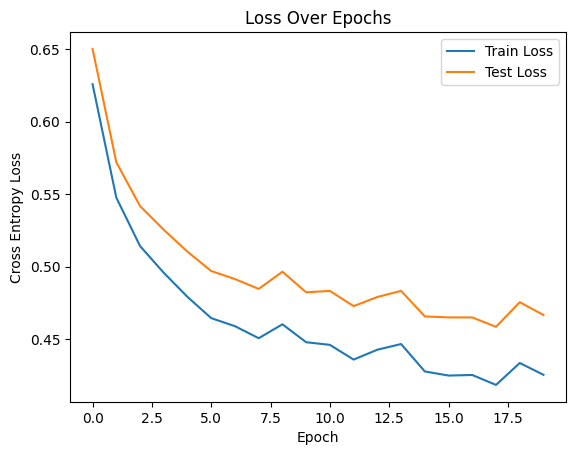

In [ ]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")
plt.title("Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.legend()
plt.show()

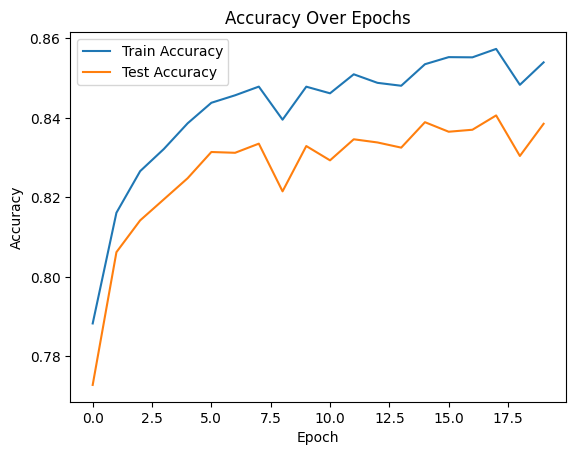

In [ ]:
plt.figure()
plt.plot(train_accs, label="Train Accuracy")
plt.plot(test_accs, label="Test Accuracy")
plt.title("Accuracy Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# 5. Prediction

In [ ]:
# Cell: Class labels
fashion_labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

In [ ]:
# Cell: Prediction function

def predict(X, W, b):
    y_hat = forward(X, W, b)
    return np.argmax(y_hat, axis=1)

In [ ]:
# Cell: Visualize predictions

def show_predictions(X, y_true, W, b, num_images=10):
    y_pred = predict(X[:num_images], W, b)
    
    plt.figure(figsize=(15, 3))
    
    for i in range(num_images):
        plt.subplot(1, num_images, i + 1)
        plt.imshow(X[i].reshape(28, 28), cmap="gray")
        
        true_label = fashion_labels[y_true[i]]
        pred_label = fashion_labels[y_pred[i]]
        
        color = "green" if y_true[i] == y_pred[i] else "red"
        plt.title(f"T:{true_label}\nP:{pred_label}", fontsize=8, color=color)
        plt.axis("off")
    
    plt.show()

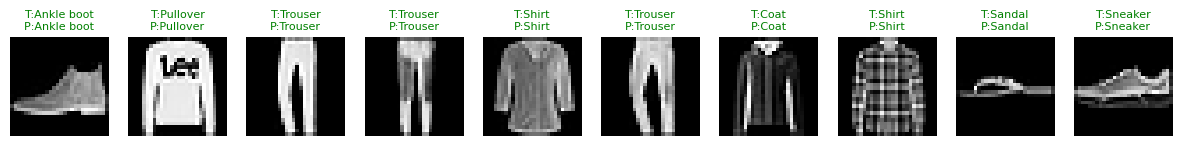

In [ ]:
show_predictions(X_test, y_test, W, b, num_images=10)

In [ ]:
y_test_pred = predict(X_test, W, b)
test_accuracy = np.mean(y_test_pred == y_test)
print("Final Test Accuracy:", test_accuracy)

Final Test Accuracy: 0.8385


#### Student Task

Write code to plot the confusion matrix.
You may use the following library to support your implementation:
https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html


-> After complete filling code, submit code back.

## Summary
By now, we have built a solid foundation in linear regression and classification. These core techniques are essential in machine learning. Next, we will explore how deep learning frameworks allow us to implement these models more efficiently and apply them to real-world problems.


 ---
<center> 

# End of Class
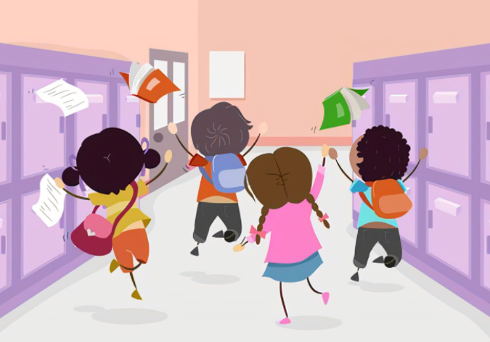
+++++++++++++++++





:)
---
</center>

